# LIDC-Y-Net Lung Image Classification — DenseNet + VQC

**Adapted from the previous DR notebook for the supplied `LIDC_Y-Net` ZIP.** This notebook treats the folders `benign`, `malignant`, and `normal` as a three-class **image-classification** dataset. The supplied ZIP contains class folders and image variants; it does not appear to provide segmentation masks, so this notebook does **not** train a Y-Net segmentation model.

### Pipeline
1. Extract and audit the dataset.
2. Select one canonical image per source ID and exclude source IDs whose images appear under conflicting labels.
3. Split source images into train/validation/test sets before training; augment only training images on the fly.
4. Fine-tune an ImageNet-pretrained DenseNet-121 with early stopping.
5. Extract DenseNet features and train a **new VQC for this dataset** using train-fitted preprocessing.
6. Tune a DenseNet/VQC probability-fusion weight using validation data only, then evaluate both models and the combined prediction on the held-out test split.
7. Export classification metrics, confusion matrices, uncertainty flags, and Grad-CAM++ examples.

**Important:** the old DR checkpoints, DR CSVs, and old DR VQC checkpoint/features are deliberately not loaded. The classes and task have changed. Results from this notebook must be measured afresh and should not be presented as clinical performance.

## 1. Environment and Google Drive

Run from top to bottom in Google Colab. Put `LIDC_Y-Net (4).zip` in the root of My Drive, or upload it when prompted. The extracted dataset and intermediate cache are kept in the Colab runtime; results and checkpoints are saved to Google Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%pip -q install timm pennylane scikit-learn joblib matplotlib pandas pillow torchvision

import os, re, json, time, math, random, warnings, zipfile
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import joblib

import torch
import torch.nn as nn
import timm
import pennylane as qml
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = torch.cuda.is_available()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 2
PIN_MEMORY = DEVICE.type == 'cuda'
print('PyTorch:', torch.__version__)
print('timm:', timm.__version__)
print('PennyLane:', qml.__version__)
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.11.0+cu130
timm: 1.0.30
PennyLane: 0.45.1
Device: cuda
GPU: Tesla T4


## 2. Dataset paths, extraction, and class definitions

If the ZIP is stored in a different Drive folder, update `DATA_ZIP` below. The expected extracted structure is `LIDC_Y-Net/benign`, `LIDC_Y-Net/malignant`, and `LIDC_Y-Net/normal`.

In [ ]:
# --- Change this path if the ZIP is stored elsewhere in Google Drive ---
DATA_ZIP = Path('/content/drive/MyDrive/LIDC_Y-Net.zip')
EXTRACT_DIR = Path('/content/lidc_y_net_extracted')
DATA_ROOT = EXTRACT_DIR / 'LIDC_Y-Net'

RESULTS_DIR = Path('/content/drive/MyDrive/LIDC_YNet_Results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['benign', 'malignant', 'normal']
CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

if not DATA_ZIP.exists():
    alternatives = [
        Path('/content/drive/MyDrive/LIDC_Y-Net.zip'),
        Path('/content/LIDC_Y-Net.zip'),
        Path('/content/LIDC_Y-Net.zip'),
    ]
    found = next((p for p in alternatives if p.exists()), None)
    if found is not None:
        DATA_ZIP = found
    else:
        from google.colab import files
        print('ZIP not found in the expected Drive locations. Upload LIDC_Y-Net.zip now.')
        uploaded = files.upload()
        zips = [Path('/content') / name for name in uploaded if name.lower().endswith('.zip')]
        if not zips:
            raise FileNotFoundError('No ZIP was uploaded. Upload the LIDC_Y-Net dataset ZIP and rerun this cell.')
        DATA_ZIP = zips[0]

if not all((DATA_ROOT / c).is_dir() for c in CLASS_NAMES):
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'Extracting {DATA_ZIP} to {EXTRACT_DIR} ...')
    with zipfile.ZipFile(DATA_ZIP) as zf:
        zf.extractall(EXTRACT_DIR)

if not all((DATA_ROOT / c).is_dir() for c in CLASS_NAMES):
    # Locate a nested folder containing all three class subfolders.
    candidates = [p for p in EXTRACT_DIR.rglob('*') if p.is_dir() and all((p / c).is_dir() for c in CLASS_NAMES)]
    if candidates:
        DATA_ROOT = candidates[0]
    else:
        raise FileNotFoundError(
            f'Could not find folders {CLASS_NAMES} under {EXTRACT_DIR}. '
            'Inspect the ZIP structure and update DATA_ROOT.'
        )

print('Dataset ZIP:', DATA_ZIP)
print('Dataset root:', DATA_ROOT)
print('Results folder:', RESULTS_DIR)

Dataset ZIP: /content/drive/MyDrive/LIDC_Y-Net.zip
Dataset root: /content/lidc_y_net_extracted/LIDC_Y-Net
Results folder: /content/drive/MyDrive/LIDC_YNet_Results


## 3. Audit variants and create leakage-aware splits

The supplied filenames include derived variants such as `cropped`, `hflip`, `vflip`, and `rotateflip`. To avoid counting transformed copies as independent test samples, this notebook selects one canonical image per source ID (the filename prefix before `Resized`) and uses on-the-fly augmentation only for training. If the same source ID appears under more than one class, that ID is excluded because its label is ambiguous in this ZIP. The split is made at the source-image level, before training.

In [ ]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
records = []

for class_name in CLASS_NAMES:
    class_dir = DATA_ROOT / class_name
    if not class_dir.is_dir():
        raise FileNotFoundError(f'Missing class folder: {class_dir}')
    for path in sorted(class_dir.rglob('*')):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
            stem = path.stem
            # Variants in this dataset are named like <source_id>Resized..., so all variants share source_id.
            source_id = stem.split('Resized', 1)[0] if 'Resized' in stem else stem
            variant_suffix = stem.split('Resized', 1)[1].lower() if 'Resized' in stem else ''
            records.append({
                'class_name': class_name,
                'label': CLASS_TO_ID[class_name],
                'source_id': source_id,
                'variant_suffix': variant_suffix,
                'path': str(path),
                'filename': path.name,
            })

all_df = pd.DataFrame(records)
if all_df.empty:
    raise RuntimeError(f'No image files found below {DATA_ROOT}')

print('All image files by class (includes derivatives):')
display(all_df.groupby('class_name').size().reindex(CLASS_NAMES, fill_value=0).rename('image_files').to_frame())

# Identify IDs that occur under more than one label and exclude those IDs from every split.
labels_per_source = all_df.groupby('source_id')['class_name'].agg(lambda x: sorted(set(x)))
conflicting_ids = set(labels_per_source[labels_per_source.map(len) > 1].index)
conflicts_df = all_df[all_df['source_id'].isin(conflicting_ids)].sort_values(['source_id', 'class_name', 'filename'])
conflicts_df.to_csv(RESULTS_DIR / 'excluded_conflicting_source_ids.csv', index=False)

clean_df = all_df[~all_df['source_id'].isin(conflicting_ids)].copy()

# Canonical file selection: original Resized image (suffix '') or original Resizedn image (suffix 'n').
canonical_rows = []
for (class_name, source_id), group in clean_df.groupby(['class_name', 'source_id'], sort=True):
    candidates = group[group['variant_suffix'].isin(['', 'n'])]
    if candidates.empty:
        # Fallback only if no recognized canonical filename exists; log which file was selected.
        candidates = group.assign(_suffix_len=group['variant_suffix'].str.len()).sort_values(['_suffix_len', 'filename']).head(1)
    else:
        candidates = candidates.assign(_priority=candidates['variant_suffix'].map({'': 0, 'n': 1})).sort_values(['_priority', 'filename']).head(1)
    canonical_rows.append(candidates.iloc[0].drop(labels=[x for x in ['_suffix_len', '_priority'] if x in candidates.columns]).to_dict())

manifest = pd.DataFrame(canonical_rows).drop_duplicates(subset=['source_id']).reset_index(drop=True)
if manifest['source_id'].duplicated().any():
    raise AssertionError('Source IDs are not unique after canonical selection; inspect the filename grouping logic.')

# Deterministic approximately 70/15/15 split, stratified by class at the source-image level.
train_df, temp_df = train_test_split(
    manifest, test_size=0.30, random_state=SEED, stratify=manifest['label']
)
valid_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df['label']
)
train_df = train_df.copy().assign(split='train').sort_values('source_id').reset_index(drop=True)
valid_df = valid_df.copy().assign(split='valid').sort_values('source_id').reset_index(drop=True)
test_df = test_df.copy().assign(split='test').sort_values('source_id').reset_index(drop=True)

split_manifest = pd.concat([train_df, valid_df, test_df], ignore_index=True)
# A final safety check: no source ID should occur across splits.
assert split_manifest.groupby('source_id')['split'].nunique().max() == 1
split_manifest.to_csv(RESULTS_DIR / 'dataset_split_manifest.csv', index=False)

print(f'Raw image files: {len(all_df)}')
print(f'Conflicting source IDs excluded: {len(conflicting_ids)} -> {sorted(conflicting_ids)}')
print(f'Canonical source images retained: {len(manifest)}')
print(f'Train / validation / test: {len(train_df)} / {len(valid_df)} / {len(test_df)}')
display(pd.crosstab(split_manifest['split'], split_manifest['class_name']).reindex(index=['train','valid','test'], columns=CLASS_NAMES, fill_value=0))
print('Saved manifest:', RESULTS_DIR / 'dataset_split_manifest.csv')
print('Saved conflicts audit:', RESULTS_DIR / 'excluded_conflicting_source_ids.csv')

All image files by class (includes derivatives):


,image_files
class_name,
benign,592
malignant,666
normal,666


Raw image files: 1924
Conflicting source IDs excluded: 1 -> ['11_29']
Canonical source images retained: 319
Train / validation / test: 223 / 48 / 48


class_name,benign,malignant,normal
split,,,
train,69,77,77
valid,15,16,17
test,15,17,16


Saved manifest: /content/drive/MyDrive/LIDC_YNet_Results/dataset_split_manifest.csv
Saved conflicts audit: /content/drive/MyDrive/LIDC_YNet_Results/excluded_conflicting_source_ids.csv


## 4. Image datasets and DataLoaders

The canonical images are resized and normalized using ImageNet statistics. Random augmentation is applied only while training DenseNet; validation and test images are deterministic. For this small dataset, transfer learning is strongly preferred over training a deep network from scratch.

In [ ]:
IMAGE_SIZE = 224
BATCH_SIZE = 16
TRAIN_BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class LungImageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform
        self.paths = self.df['path'].tolist()
        self.labels = self.df['label'].astype(int).to_numpy()
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.paths[idx]
        try:
            with Image.open(path) as im:
                image = im.convert('RGB')
        except Exception as e:
            raise RuntimeError(f'Could not read image: {path}') from e
        return self.transform(image), int(self.labels[idx]), idx

train_ds = LungImageDataset(train_df, train_transform)
train_eval_ds = LungImageDataset(train_df, eval_transform)  # no augmentation for VQC feature generation
valid_ds = LungImageDataset(valid_df, eval_transform)
test_ds = LungImageDataset(test_df, eval_transform)

train_loader = DataLoader(train_ds, batch_size=TRAIN_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
train_eval_loader = DataLoader(train_eval_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

y_train = train_df['label'].astype(int).to_numpy()
y_valid = valid_df['label'].astype(int).to_numpy()
y_test = test_df['label'].astype(int).to_numpy()
print('Class mapping:', CLASS_TO_ID)
print('Unique canonical images:', len(train_ds), len(valid_ds), len(test_ds))

Class mapping: {'benign': 0, 'malignant': 1, 'normal': 2}
Unique canonical images: 223 48 48


## 5. Train DenseNet-121 for three-class classification

This starts from ImageNet-pretrained DenseNet-121, replaces the classifier with three outputs, and fine-tunes on the new dataset. Early stopping selects the best validation Macro-F1 checkpoint. No DR checkpoints are loaded.

In [ ]:
EPOCHS = 100
PATIENCE = 98
MIN_DELTA = 0.001
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
USE_IMAGENET_PRETRAINED = True

DENSENET_CKPT = RESULTS_DIR / 'densenet121_lung3class_best.pt'
DENSENET_HISTORY = RESULTS_DIR / 'densenet121_training_history.csv'

try:
    model = timm.create_model(
        'densenet121', pretrained=USE_IMAGENET_PRETRAINED,
        num_classes=NUM_CLASSES, drop_rate=0.2
    )
except Exception as e:
    raise RuntimeError(
        'Could not create DenseNet-121 with pretrained ImageNet weights. '
        'Check Colab internet access/model-weight download, or set USE_IMAGENET_PRETRAINED=False '
        '(training from scratch on this small dataset is not recommended).'
    ) from e
model = model.to(DEVICE)

class_counts = np.bincount(y_train, minlength=NUM_CLASSES).astype(np.float32)
class_weights = 1.0 / np.sqrt(np.maximum(class_counts, 1.0))
class_weights = class_weights / class_weights.mean()
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE))
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
use_amp = DEVICE.type == 'cuda'
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

best_val_macro_f1 = -1.0
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):
    started = time.time()
    model.train()
    total_loss, seen = 0.0, 0
    for xb, yb, _ in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            logits = model(xb)
            loss = criterion(logits, yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += float(loss.detach()) * len(yb)
        seen += len(yb)

    model.eval()
    val_true, val_pred = [], []
    with torch.inference_mode():
        for xb, yb, _ in valid_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                logits = model(xb)
            val_pred.extend(logits.argmax(1).cpu().numpy().tolist())
            val_true.extend(yb.numpy().tolist())

    val_macro = f1_score(val_true, val_pred, average='macro', zero_division=0)
    val_acc = accuracy_score(val_true, val_pred)
    row = {
        'epoch': epoch,
        'train_loss': total_loss / max(seen, 1),
        'validation_accuracy': val_acc,
        'validation_macro_f1': val_macro,
        'seconds': time.time() - started,
    }
    history.append(row)
    print(f"Epoch {epoch:03d}/{EPOCHS} | loss={row['train_loss']:.4f} | val_acc={val_acc:.4f} | val_macro_F1={val_macro:.4f} | {row['seconds']:.1f}s")

    if val_macro > best_val_macro_f1 + MIN_DELTA:
        best_val_macro_f1 = val_macro
        epochs_without_improvement = 0
        torch.save({
            'model_state_dict': model.state_dict(),
            'class_names': CLASS_NAMES,
            'num_classes': NUM_CLASSES,
            'image_size': IMAGE_SIZE,
            'best_validation_macro_f1': best_val_macro_f1,
            'epoch': epoch,
            'seed': SEED,
        }, DENSENET_CKPT)
        print('  Saved best DenseNet checkpoint:', DENSENET_CKPT)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f'Early stopping at epoch {epoch}; no validation Macro-F1 improvement for {PATIENCE} epochs.')
        break

pd.DataFrame(history).to_csv(DENSENET_HISTORY, index=False)
if not DENSENET_CKPT.exists():
    raise RuntimeError('DenseNet checkpoint was not saved; inspect training logs.')
print('Best validation Macro-F1:', best_val_macro_f1)
print('Best checkpoint:', DENSENET_CKPT)
print('Training history:', DENSENET_HISTORY)

/tmp/ipykernel_747/4139477457.py:30: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


Epoch 001/100 | loss=1.0500 | val_acc=0.4167 | val_macro_F1=0.3394 | 2.8s
  Saved best DenseNet checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/densenet121_lung3class_best.pt
Epoch 002/100 | loss=0.7958 | val_acc=0.7500 | val_macro_F1=0.7521 | 4.8s
  Saved best DenseNet checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/densenet121_lung3class_best.pt
Epoch 003/100 | loss=0.5776 | val_acc=0.7292 | val_macro_F1=0.6907 | 4.8s
Epoch 004/100 | loss=0.3976 | val_acc=0.8750 | val_macro_F1=0.8758 | 5.2s
  Saved best DenseNet checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/densenet121_lung3class_best.pt
Epoch 005/100 | loss=0.3229 | val_acc=0.9167 | val_macro_F1=0.9169 | 4.8s
  Saved best DenseNet checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/densenet121_lung3class_best.pt
Epoch 006/100 | loss=0.2253 | val_acc=0.9167 | val_macro_F1=0.9189 | 4.5s
  Saved best DenseNet checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/densenet121_lung3class_best.pt
Epoch 007/100 | loss=0.205

## 6. Load the best DenseNet checkpoint and evaluate its outputs

The saved checkpoint is reloaded before features are extracted for VQC. This ensures VQC uses features from the finalized DenseNet checkpoint, not from an intermediate epoch.

In [ ]:
checkpoint = torch.load(DENSENET_CKPT, map_location='cpu', weights_only=False)
model = timm.create_model('densenet121', pretrained=False, num_classes=NUM_CLASSES, drop_rate=0.2)
model.load_state_dict(checkpoint['model_state_dict'], strict=True)
model = model.to(DEVICE).eval()
print('Loaded DenseNet checkpoint from epoch:', checkpoint.get('epoch'))
print('Checkpoint validation Macro-F1:', checkpoint.get('best_validation_macro_f1'))

@torch.inference_mode()
def get_probabilities(net, loader):
    all_probs, all_labels = [], []
    net.eval()
    for xb, yb, _ in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == 'cuda')):
            logits = net(xb)
        all_probs.append(torch.softmax(logits, dim=1).cpu().numpy())
        all_labels.extend(yb.numpy().tolist())
    return np.concatenate(all_probs, axis=0), np.asarray(all_labels, dtype=np.int64)

val_dense_probs, y_valid_check = get_probabilities(model, valid_loader)
test_dense_probs, y_test_check = get_probabilities(model, test_loader)
assert np.array_equal(y_valid_check, y_valid)
assert np.array_equal(y_test_check, y_test)
print('DenseNet validation/test probability arrays:', val_dense_probs.shape, test_dense_probs.shape)

Loaded DenseNet checkpoint from epoch: 15
Checkpoint validation Macro-F1: 1.0
DenseNet validation/test probability arrays: (48, 3) (48, 3)


## 7. Extract DenseNet embeddings and fit VQC preprocessing

The VQC is newly trained for these three classes. We use the finalized DenseNet's pooled feature vector, then fit `StandardScaler`, 4-component PCA, and an angle scaler on **training embeddings only**. Validation and test data are transformed with those same fitted objects to avoid preprocessing leakage.

In [ ]:
@torch.inference_mode()
def extract_densenet_embeddings(net, loader):
    net.eval()
    feature_batches, label_batches = [], []
    for xb, yb, _ in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        fmap = net.forward_features(xb)
        # Prefer timm's pre-logit embedding API; keep a compatibility fallback for older timm versions.
        try:
            embeddings = net.forward_head(fmap, pre_logits=True)
        except TypeError:
            pooled = net.global_pool(fmap)
            embeddings = pooled.flatten(1) if pooled.ndim > 2 else pooled
        feature_batches.append(embeddings.detach().cpu().numpy().astype(np.float32))
        label_batches.extend(yb.numpy().tolist())
    return np.concatenate(feature_batches, axis=0), np.asarray(label_batches, dtype=np.int64)

X_train_emb, y_train_feature = extract_densenet_embeddings(model, train_eval_loader)
X_valid_emb, y_valid_feature = extract_densenet_embeddings(model, valid_loader)
X_test_emb, y_test_feature = extract_densenet_embeddings(model, test_loader)
assert np.array_equal(y_train_feature, y_train)
assert np.array_equal(y_valid_feature, y_valid)
assert np.array_equal(y_test_feature, y_test)

N_QUBITS = 4
if X_train_emb.shape[1] < N_QUBITS:
    raise ValueError(f'Need at least {N_QUBITS} DenseNet feature dimensions; got {X_train_emb.shape[1]}')
feature_scaler = StandardScaler()
X_train_std = feature_scaler.fit_transform(X_train_emb)
X_valid_std = feature_scaler.transform(X_valid_emb)
X_test_std = feature_scaler.transform(X_test_emb)

pca = PCA(n_components=N_QUBITS, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_std)
X_valid_pca = pca.transform(X_valid_std)
X_test_pca = pca.transform(X_test_std)

angle_scaler = MinMaxScaler(feature_range=(0.0, np.pi))
X_train_vqc = np.clip(angle_scaler.fit_transform(X_train_pca), 0.0, np.pi).astype(np.float32)
X_valid_vqc = np.clip(angle_scaler.transform(X_valid_pca), 0.0, np.pi).astype(np.float32)
X_test_vqc = np.clip(angle_scaler.transform(X_test_pca), 0.0, np.pi).astype(np.float32)

PREPROCESSOR_PATH = RESULTS_DIR / 'vqc_feature_preprocessing.joblib'
joblib.dump({'feature_scaler': feature_scaler, 'pca': pca, 'angle_scaler': angle_scaler}, PREPROCESSOR_PATH)
np.savez_compressed(
    RESULTS_DIR / 'lung_vqc_features.npz',
    X_train=X_train_vqc, y_train=y_train_feature,
    X_valid=X_valid_vqc, y_valid=y_valid_feature,
    X_test=X_test_vqc, y_test=y_test_feature,
)
print('DenseNet embedding shape:', X_train_emb.shape)
print('VQC input shape:', X_train_vqc.shape, X_valid_vqc.shape, X_test_vqc.shape)
print('PCA explained variance ratio:', pca.explained_variance_ratio_, 'sum=', pca.explained_variance_ratio_.sum())
print('Saved preprocessing:', PREPROCESSOR_PATH)

DenseNet embedding shape: (223, 1024)
VQC input shape: (223, 4) (48, 4) (48, 4)
PCA explained variance ratio: [0.1537679  0.11466872 0.04291685 0.04143149] sum= 0.35278493
Saved preprocessing: /content/drive/MyDrive/LIDC_YNet_Results/vqc_feature_preprocessing.joblib


## 8. Train a new 4-qubit VQC for the lung-image classes

This cell trains VQC from scratch on the new DenseNet feature representation. It does not load the old DR VQC checkpoint. Early stopping uses validation Macro-F1. The quantum circuit is a small research prototype; results depend on the available sample size and circuit/training settings.

In [ ]:
N_LAYERS = 2
VQC_EPOCHS = 100
VQC_PATIENCE = 98
VQC_LR = 0.02
VQC_BATCH_SIZE = 16
VQC_CKPT = RESULTS_DIR / 'vqc_lung3class_best.pt'
VQC_HISTORY = RESULTS_DIR / 'vqc_lung3class_training_history.csv'

q_device = qml.device('default.qubit', wires=N_QUBITS)
@qml.qnode(q_device, interface='torch', diff_method='backprop')
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation='Y')
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

class VQCClassifier(nn.Module):
    def __init__(self, n_layers=N_LAYERS):
        super().__init__()
        self.quantum = qml.qnn.TorchLayer(
            quantum_circuit,
            weight_shapes={'weights': (n_layers, N_QUBITS, 3)}
        )
        self.classifier = nn.Linear(N_QUBITS, NUM_CLASSES)
    def forward(self, x):
        return self.classifier(self.quantum(x))

vqc_model = VQCClassifier().to('cpu')  # PennyLane default.qubit runs on CPU
vqc_train_ds = TensorDataset(torch.from_numpy(X_train_vqc), torch.from_numpy(y_train_feature))
vqc_valid_ds = TensorDataset(torch.from_numpy(X_valid_vqc), torch.from_numpy(y_valid_feature))
vqc_train_loader = DataLoader(vqc_train_ds, batch_size=VQC_BATCH_SIZE, shuffle=True)
vqc_valid_loader = DataLoader(vqc_valid_ds, batch_size=VQC_BATCH_SIZE, shuffle=False)

vqc_class_counts = np.bincount(y_train_feature, minlength=NUM_CLASSES).astype(np.float32)
vqc_class_weights = 1.0 / np.sqrt(np.maximum(vqc_class_counts, 1.0))
vqc_class_weights = vqc_class_weights / vqc_class_weights.mean()
vqc_criterion = nn.CrossEntropyLoss(weight=torch.tensor(vqc_class_weights, dtype=torch.float32))
vqc_optimizer = torch.optim.Adam(vqc_model.parameters(), lr=VQC_LR, weight_decay=1e-4)

best_vqc_macro = -1.0
vqc_wait = 0
vqc_history = []

for epoch in range(1, VQC_EPOCHS + 1):
    started = time.time()
    vqc_model.train()
    total_loss, seen = 0.0, 0
    for xb, yb in vqc_train_loader:
        xb, yb = xb.float(), yb.long()
        vqc_optimizer.zero_grad(set_to_none=True)
        logits = vqc_model(xb)
        loss = vqc_criterion(logits, yb)
        loss.backward()
        vqc_optimizer.step()
        total_loss += float(loss.detach()) * len(yb)
        seen += len(yb)

    vqc_model.eval()
    va_true, va_pred = [], []
    with torch.inference_mode():
        for xb, yb in vqc_valid_loader:
            logits = vqc_model(xb.float())
            va_pred.extend(logits.argmax(1).numpy().tolist())
            va_true.extend(yb.numpy().tolist())
    val_macro = f1_score(va_true, va_pred, average='macro', zero_division=0)
    val_acc = accuracy_score(va_true, va_pred)
    row = {'epoch': epoch, 'train_loss': total_loss / max(seen, 1), 'validation_accuracy': val_acc,
           'validation_macro_f1': val_macro, 'seconds': time.time() - started}
    vqc_history.append(row)
    print(f"VQC epoch {epoch:02d}/{VQC_EPOCHS} | loss={row['train_loss']:.4f} | val_acc={val_acc:.4f} | val_macro_F1={val_macro:.4f} | {row['seconds']:.1f}s")

    if val_macro > best_vqc_macro + 0.001:
        best_vqc_macro = val_macro
        vqc_wait = 0
        torch.save({
            'model_state_dict': vqc_model.state_dict(),
            'n_qubits': N_QUBITS,
            'n_layers': N_LAYERS,
            'num_classes': NUM_CLASSES,
            'class_names': CLASS_NAMES,
            'best_validation_macro_f1': best_vqc_macro,
            'epoch': epoch,
        }, VQC_CKPT)
        print('  Saved best VQC checkpoint:', VQC_CKPT)
    else:
        vqc_wait += 1

    if vqc_wait >= VQC_PATIENCE:
        print(f'VQC early stopping at epoch {epoch}.')
        break

pd.DataFrame(vqc_history).to_csv(VQC_HISTORY, index=False)
if not VQC_CKPT.exists():
    raise RuntimeError('VQC checkpoint was not saved; inspect training logs.')
vqc_saved = torch.load(VQC_CKPT, map_location='cpu', weights_only=False)
vqc_model.load_state_dict(vqc_saved['model_state_dict'], strict=True)
vqc_model.eval()
print('Loaded best VQC checkpoint from epoch:', vqc_saved.get('epoch'))
print('Best VQC validation Macro-F1:', vqc_saved.get('best_validation_macro_f1'))

VQC epoch 01/100 | loss=1.0816 | val_acc=0.3958 | val_macro_F1=0.3028 | 0.3s
  Saved best VQC checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/vqc_lung3class_best.pt
VQC epoch 02/100 | loss=0.9116 | val_acc=0.9167 | val_macro_F1=0.9106 | 0.3s
  Saved best VQC checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/vqc_lung3class_best.pt
VQC epoch 03/100 | loss=0.7013 | val_acc=0.9375 | val_macro_F1=0.9338 | 0.3s
  Saved best VQC checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/vqc_lung3class_best.pt
VQC epoch 04/100 | loss=0.5231 | val_acc=0.9375 | val_macro_F1=0.9338 | 0.3s
VQC epoch 05/100 | loss=0.3977 | val_acc=0.9375 | val_macro_F1=0.9338 | 0.3s
VQC epoch 06/100 | loss=0.3104 | val_acc=0.9375 | val_macro_F1=0.9338 | 0.3s
VQC epoch 07/100 | loss=0.2593 | val_acc=0.9167 | val_macro_F1=0.9141 | 0.3s
VQC epoch 08/100 | loss=0.2140 | val_acc=0.9375 | val_macro_F1=0.9338 | 0.3s
VQC epoch 09/100 | loss=0.1864 | val_acc=0.9375 | val_macro_F1=0.9338 | 0.3s
VQC epoch 10/100 | loss=0.16

## 9. Combine DenseNet and VQC predictions using validation-only fusion

DenseNet and VQC both contribute to the combined output through probability-level late fusion. The DenseNet probability weight is selected from a small, predefined grid using **validation Macro-F1 only**; the VQC weight is `1 - DenseNet weight`, and both weights are constrained to be nonzero. Test labels are not used to select the fusion weight.

In [ ]:
@torch.inference_mode()
def vqc_probabilities(net, x_np, batch_size=16):
    net.eval()
    out = []
    for start in range(0, len(x_np), batch_size):
        xb = torch.from_numpy(x_np[start:start + batch_size]).float()
        logits = net(xb)
        out.append(torch.softmax(logits, dim=1).numpy())
    return np.concatenate(out, axis=0)

vqc_valid_probs = vqc_probabilities(vqc_model, X_valid_vqc)
vqc_test_probs = vqc_probabilities(vqc_model, X_test_vqc)
assert vqc_valid_probs.shape == val_dense_probs.shape
assert vqc_test_probs.shape == test_dense_probs.shape

fusion_candidates = np.round(np.arange(0.10, 0.901, 0.05), 2)
fusion_rows = []
for dense_weight in fusion_candidates:
    fused_valid = dense_weight * val_dense_probs + (1.0 - dense_weight) * vqc_valid_probs
    fused_pred = fused_valid.argmax(axis=1)
    fusion_rows.append({
        'densenet_weight': float(dense_weight),
        'vqc_weight': float(1.0 - dense_weight),
        'validation_macro_f1': f1_score(y_valid, fused_pred, average='macro', zero_division=0),
        'validation_accuracy': accuracy_score(y_valid, fused_pred),
    })
fusion_df = pd.DataFrame(fusion_rows).sort_values(
    ['validation_macro_f1', 'validation_accuracy'], ascending=False
).reset_index(drop=True)
BEST_DENSENET_WEIGHT = float(fusion_df.iloc[0]['densenet_weight'])
BEST_VQC_WEIGHT = 1.0 - BEST_DENSENET_WEIGHT
fusion_df.to_csv(RESULTS_DIR / 'fusion_weight_validation_search.csv', index=False)

combined_test_probs = BEST_DENSENET_WEIGHT * test_dense_probs + BEST_VQC_WEIGHT * vqc_test_probs
print(f'Selected validation fusion weights: DenseNet={BEST_DENSENET_WEIGHT:.2f}, VQC={BEST_VQC_WEIGHT:.2f}')
print('Validation fusion search saved:', RESULTS_DIR / 'fusion_weight_validation_search.csv')
print('These are validation-tuned weights; the test set has not been used for tuning.')

Selected validation fusion weights: DenseNet=0.90, VQC=0.10
Validation fusion search saved: /content/drive/MyDrive/LIDC_YNet_Results/fusion_weight_validation_search.csv
These are validation-tuned weights; the test set has not been used for tuning.


## 10. Final held-out test comparison and confusion matrices

The classes are nominal (`benign`, `malignant`, `normal`), not an ordinal severity scale, so this notebook does not report quadratic weighted kappa (QWK). The test set is evaluated once after model selection and fusion-weight selection.

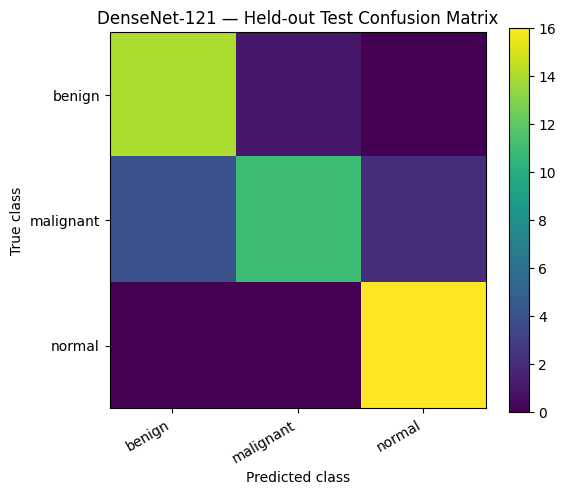


DenseNet-121 classification report
              precision    recall  f1-score   support

      benign     0.7778    0.9333    0.8485        15
   malignant     0.9167    0.6471    0.7586        17
      normal     0.8889    1.0000    0.9412        16

    accuracy                         0.8542        48
   macro avg     0.8611    0.8601    0.8494        48
weighted avg     0.8640    0.8542    0.8476        48



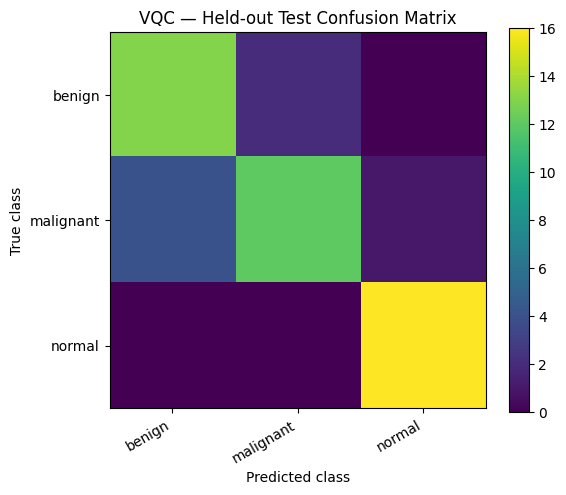


VQC classification report
              precision    recall  f1-score   support

      benign     0.7647    0.8667    0.8125        15
   malignant     0.8571    0.7059    0.7742        17
      normal     0.9412    1.0000    0.9697        16

    accuracy                         0.8542        48
   macro avg     0.8543    0.8575    0.8521        48
weighted avg     0.8563    0.8542    0.8513        48



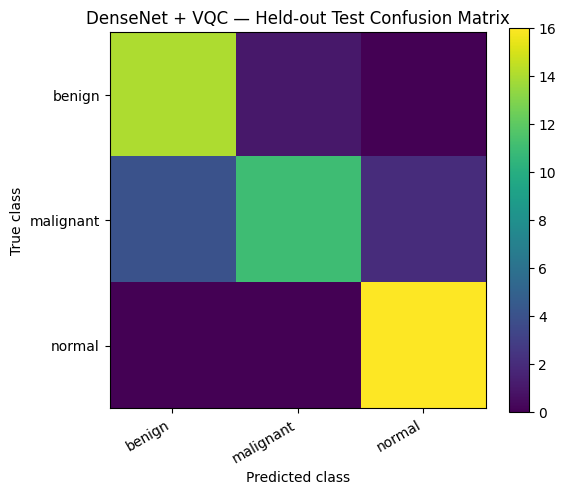


DenseNet + VQC classification report
              precision    recall  f1-score   support

      benign     0.7778    0.9333    0.8485        15
   malignant     0.9167    0.6471    0.7586        17
      normal     0.8889    1.0000    0.9412        16

    accuracy                         0.8542        48
   macro avg     0.8611    0.8601    0.8494        48
weighted avg     0.8640    0.8542    0.8476        48


OVERALL HELD-OUT TEST COMPARISON
         Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
  DenseNet-121    0.8542           0.8611        0.8601    0.8494       0.8476
           VQC    0.8542           0.8543        0.8575    0.8521       0.8513
DenseNet + VQC    0.8542           0.8611        0.8601    0.8494       0.8476

CLASS-WISE F1
Model      DenseNet + VQC  DenseNet-121     VQC
Class                                          
benign             0.8485        0.8485  0.8125
malignant          0.7586        0.7586  0.7742
normal             0.941

In [ ]:
model_probabilities = {
    'DenseNet-121': test_dense_probs,
    'VQC': vqc_test_probs,
    'DenseNet + VQC': combined_test_probs,
}
summary_rows = []
classwise_rows = []

for name, probs in model_probabilities.items():
    pred = probs.argmax(axis=1)
    summary_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Macro Precision': precision_score(y_test, pred, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, pred, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, pred, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_test, pred, average='weighted', zero_division=0),
    })
    report = classification_report(y_test, pred, labels=list(range(NUM_CLASSES)),
                                   target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    for class_name in CLASS_NAMES:
        classwise_rows.append({
            'Model': name, 'Class': class_name,
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1-score': report[class_name]['f1-score'],
            'Support': int(report[class_name]['support']),
        })
    cm = confusion_matrix(y_test, pred, labels=list(range(NUM_CLASSES)))
    safe = name.lower().replace(' ', '_').replace('+', 'plus').replace('-', '_')
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RESULTS_DIR / f'{safe}_confusion_matrix.csv')
    pd.DataFrame({
        'source_id': test_df['source_id'].tolist(),
        'true_class': [CLASS_NAMES[int(v)] for v in y_test],
        'predicted_class': [CLASS_NAMES[int(v)] for v in pred],
        'confidence': probs.max(axis=1),
    }).to_csv(RESULTS_DIR / f'{safe}_test_predictions.csv', index=False)
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, interpolation='nearest')
    plt.title(f'{name} — Held-out Test Confusion Matrix')
    plt.colorbar()
    plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=30, ha='right')
    plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
    plt.xlabel('Predicted class')
    plt.ylabel('True class')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f'{safe}_confusion_matrix.png', dpi=180)
    plt.show()
    plt.close()
    print(f'\n{name} classification report')
    print(classification_report(y_test, pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES,
                                digits=4, zero_division=0))

summary_df = pd.DataFrame(summary_rows)
classwise_df = pd.DataFrame(classwise_rows)
summary_df.to_csv(RESULTS_DIR / 'final_test_model_comparison.csv', index=False)
classwise_df.to_csv(RESULTS_DIR / 'final_test_classwise_comparison.csv', index=False)
print('\nOVERALL HELD-OUT TEST COMPARISON')
print(summary_df.round(4).to_string(index=False))
print('\nCLASS-WISE F1')
print(classwise_df.pivot(index='Class', columns='Model', values='F1-score').round(4).to_string())
print('\nSaved test metrics and predictions to:', RESULTS_DIR)

## 11. Neuro-symbolic-style uncertainty flags

Because the new task has no ordered DR grades, the old adjacent-grade rules have been removed. This section applies transparent, configurable confidence/entropy flags to the **combined DenseNet + VQC probabilities**. These are illustrative uncertainty indicators, not validated clinical rules or a diagnostic recommendation system.

In [ ]:
NS_MIN_CONFIDENCE = 0.60
NS_MAX_NORMALIZED_ENTROPY = 0.75

def uncertainty_flags(prob_row):
    p = np.asarray(prob_row, dtype=np.float64)
    p = np.clip(p, 1e-12, 1.0)
    p = p / p.sum()
    pred = int(np.argmax(p))
    confidence = float(p[pred])
    entropy = float(-(p * np.log(p)).sum())
    normalized_entropy = entropy / math.log(NUM_CLASSES)
    rules = []
    if confidence < NS_MIN_CONFIDENCE:
        rules.append('LOW_CONFIDENCE')
    if normalized_entropy > NS_MAX_NORMALIZED_ENTROPY:
        rules.append('HIGH_UNCERTAINTY')
    if not rules:
        rules.append('NO_CONFIGURED_UNCERTAINTY_FLAG')
    return {
        'predicted_class_id': pred,
        'predicted_class': CLASS_NAMES[pred],
        'confidence': confidence,
        'normalized_entropy': normalized_entropy,
        'flags': ' | '.join(rules),
        'manual_review_flag': any(x in rules for x in ['LOW_CONFIDENCE', 'HIGH_UNCERTAINTY']),
    }

ns_rows = []
for i, probs in enumerate(combined_test_probs):
    row = uncertainty_flags(probs)
    row.update({
        'source_id': test_df.iloc[i]['source_id'],
        'true_class': CLASS_NAMES[int(y_test[i])],
        'correct_prediction': row['predicted_class_id'] == int(y_test[i]),
    })
    ns_rows.append(row)
ns_df = pd.DataFrame(ns_rows)
ns_path = RESULTS_DIR / 'combined_model_uncertainty_flags.csv'
ns_df.to_csv(ns_path, index=False)
print(ns_df['manual_review_flag'].value_counts().rename(index={True: 'Flagged for review', False: 'No configured flag'}))
print('Saved:', ns_path)
display(ns_df.head(10))

manual_review_flag
No configured flag    45
Flagged for review     3
Name: count, dtype: int64
Saved: /content/drive/MyDrive/LIDC_YNet_Results/combined_model_uncertainty_flags.csv


,predicted_class_id,predicted_class,confidence,normalized_entropy,flags,manual_review_flag,source_id,true_class,correct_prediction
0,0,benign,0.987465,0.069197,NO_CONFIGURED_UNCERTAINTY_FLAG,False,000003,benign,True
1,0,benign,0.968442,0.139111,NO_CONFIGURED_UNCERTAINTY_FLAG,False,000004,benign,True
2,0,benign,0.996124,0.025421,NO_CONFIGURED_UNCERTAINTY_FLAG,False,000054,benign,True
3,0,benign,0.758937,0.611233,NO_CONFIGURED_UNCERTAINTY_FLAG,False,000075_1,benign,True
4,1,malignant,0.971402,0.135837,NO_CONFIGURED_UNCERTAINTY_FLAG,False,01_03,malignant,True
5,1,malignant,0.990706,0.053737,NO_CONFIGURED_UNCERTAINTY_FLAG,False,01_123,malignant,True
6,1,malignant,0.971979,0.133250,NO_CONFIGURED_UNCERTAINTY_FLAG,False,01_41,malignant,True
7,1,malignant,0.958198,0.183782,NO_CONFIGURED_UNCERTAINTY_FLAG,False,01_71,malignant,True
8,2,normal,0.982508,0.090753,NO_CONFIGURED_UNCERTAINTY_FLAG,False,03_07,normal,True
9,2,normal,0.957249,0.186379,NO_CONFIGURED_UNCERTAINTY_FLAG,False,03_128,normal,True


## 12. Grad-CAM++ for DenseNet-121

Grad-CAM++ produces a post-hoc localization heatmap for the selected DenseNet class. The heatmap does not establish why a model is correct, is not a segmentation mask, and is not medical evidence by itself.

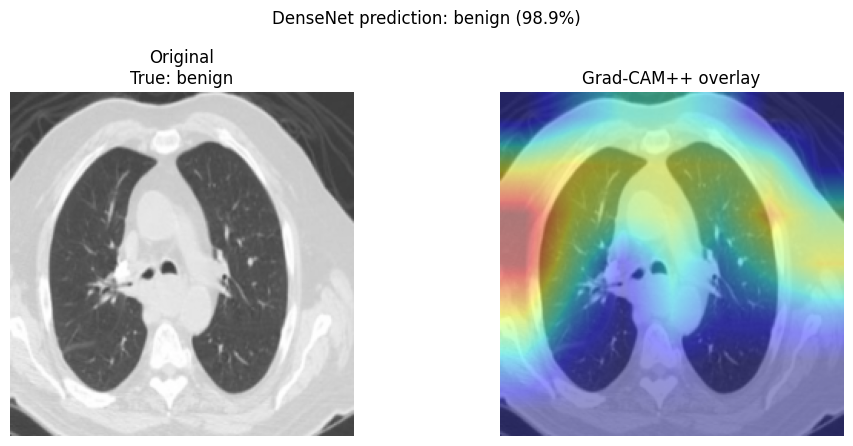

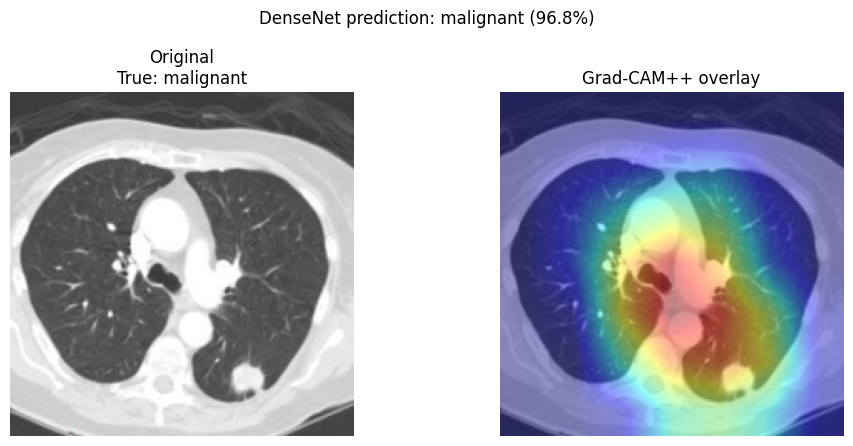

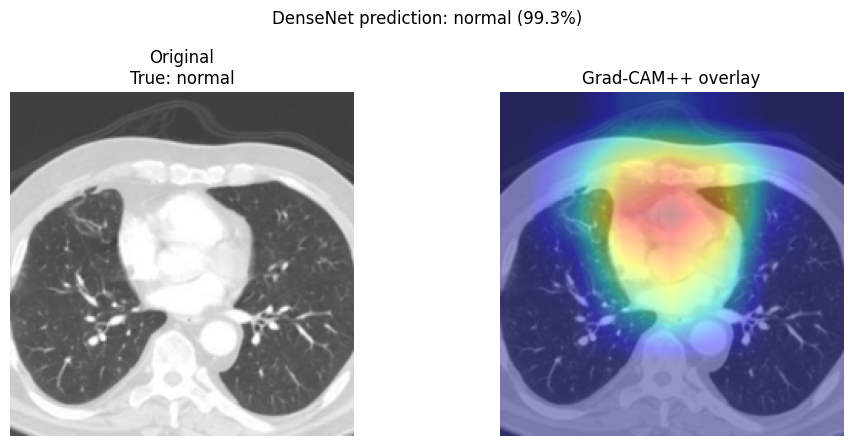

Saved Grad-CAM++ examples to: /content/drive/MyDrive/LIDC_YNet_Results


In [ ]:
cam_model = model.eval()
target_layer = cam_model.features.denseblock4
cam_store = {}

def _cam_forward_hook(module, inputs, output):
    cam_store['activations'] = output
    output.register_hook(lambda grad: cam_store.__setitem__('gradients', grad))

hook_handle = target_layer.register_forward_hook(_cam_forward_hook)

def make_gradcam_pp(input_tensor, class_idx):
    cam_model.zero_grad(set_to_none=True)
    cam_store.clear()
    logits = cam_model(input_tensor.to(DEVICE))
    logits[0, int(class_idx)].backward()
    activations = cam_store['activations'][0]
    gradients = cam_store['gradients'][0]
    grad2, grad3 = gradients.pow(2), gradients.pow(3)
    denominator = 2.0 * grad2 + (activations * grad3).sum(dim=(1, 2), keepdim=True)
    alpha = grad2 / (denominator + 1e-8)
    weights = (alpha * torch.relu(gradients)).sum(dim=(1, 2), keepdim=True)
    cam = torch.relu((weights * activations).sum(dim=0))
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    cam = torch.nn.functional.interpolate(
        cam[None, None], size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False
    )[0, 0]
    return cam.detach().cpu().numpy(), logits.detach()

def denormalize_image(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img = tensor.cpu() * std + mean
    return np.clip(img.permute(1, 2, 0).numpy(), 0, 1)

def save_gradcam_example(dataset_index, true_label):
    x, _, _ = test_ds[dataset_index]
    input_tensor = x.unsqueeze(0).to(DEVICE)
    cam_model.eval()
    with torch.enable_grad():
        initial_logits = cam_model(input_tensor)
        predicted_class = int(initial_logits.argmax(dim=1).item())
        heatmap, logits = make_gradcam_pp(input_tensor, predicted_class)
    probs = torch.softmax(logits, dim=1)[0]
    pred = int(probs.argmax().item())
    confidence = float(probs[pred].item())
    original = denormalize_image(x)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    axes[0].imshow(original)
    axes[0].set_title(f'Original\nTrue: {CLASS_NAMES[true_label]}')
    axes[1].imshow(original)
    axes[1].imshow(heatmap, cmap='jet', alpha=0.42, vmin=0, vmax=1)
    axes[1].set_title('Grad-CAM++ overlay')
    for ax in axes:
        ax.axis('off')
    fig.suptitle(f'DenseNet prediction: {CLASS_NAMES[pred]} ({confidence:.1%})')
    fig.tight_layout()
    safe = CLASS_NAMES[true_label].replace(' ', '_')
    out_path = RESULTS_DIR / f'gradcampp_true_{safe}_testidx_{dataset_index}.png'
    fig.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return {
        'test_index': dataset_index,
        'source_id': test_df.iloc[dataset_index]['source_id'],
        'true_class': CLASS_NAMES[true_label],
        'predicted_class': CLASS_NAMES[pred],
        'confidence': confidence,
        'file': str(out_path),
    }

cam_rows = []
for class_id in range(NUM_CLASSES):
    indices = np.flatnonzero(y_test == class_id)
    if len(indices):
        cam_rows.append(save_gradcam_example(int(indices[0]), class_id))

hook_handle.remove()
pd.DataFrame(cam_rows).to_csv(RESULTS_DIR / 'gradcam_plus_plus_examples.csv', index=False)
print('Saved Grad-CAM++ examples to:', RESULTS_DIR)

## 13. Final run summary and saved artifacts

Key outputs in `My Drive/LIDC_YNet_Results` include the split manifest, best DenseNet checkpoint and history, new VQC checkpoint/history, fitted VQC preprocessing objects, class-wise and overall test metrics, predictions, confusion matrices, uncertainty flags, and Grad-CAM++ examples.

### Interpretation limitations
- The ZIP appears to contain 1,924 files, including transformed variants. The notebook deliberately uses one canonical image per source ID and excludes IDs that appear in multiple classes; therefore the actual model sample count is much smaller than the file count.
- The test set is small, so metrics may be noisy. Treat this as an experimental classification pipeline, not a clinically validated system.
- This is three-class image classification only. No segmentation masks were present in the supplied ZIP listing, so no Y-Net segmentation results are produced.
- DenseNet + VQC fusion is probability-level late fusion. Its performance is reported separately and must not be claimed to improve over DenseNet unless the measured held-out metrics support that claim.

In [ ]:
print('RUN COMPLETE')
print('Dataset root:', DATA_ROOT)
print('Canonical images:', len(manifest), '| train:', len(train_df), '| valid:', len(valid_df), '| test:', len(test_df))
print('DenseNet checkpoint:', DENSENET_CKPT)
print('VQC checkpoint:', VQC_CKPT)
print('Fusion weights -> DenseNet:', BEST_DENSENET_WEIGHT, '| VQC:', BEST_VQC_WEIGHT)
print('Results directory:', RESULTS_DIR)
print('Metric table:')
display(summary_df)

RUN COMPLETE
Dataset root: /content/lidc_y_net_extracted/LIDC_Y-Net
Canonical images: 319 | train: 223 | valid: 48 | test: 48
DenseNet checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/densenet121_lung3class_best.pt
VQC checkpoint: /content/drive/MyDrive/LIDC_YNet_Results/vqc_lung3class_best.pt
Fusion weights -> DenseNet: 0.9 | VQC: 0.09999999999999998
Results directory: /content/drive/MyDrive/LIDC_YNet_Results
Metric table:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,DenseNet-121,0.854167,0.861111,0.860131,0.849427,0.847555
1,VQC,0.854167,0.854342,0.857516,0.852130,0.851332
2,DenseNet + VQC,0.854167,0.861111,0.860131,0.849427,0.847555
